# Hands-on 16: PCA untuk Merangkum Beberapa Sensor

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 5.

22 fitur time-series distandarisasi (StandardScaler) lalu direduksi ke 3 komponen utama.
Output: `data/processed/room_30days_pca.csv`.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Jalankan PCA

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/pca_room_features.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Hasil PCA disimpan ke: data/processed/room_30days_pca.csv (4314 baris)
             timestamp device_id       pc1       pc2       pc3
0  2026-01-01 01:00:00    room01 -5.346195  0.538122  1.314684
1  2026-01-01 01:10:00    room01 -5.582391  0.553816 -0.418140
2  2026-01-01 01:20:00    room01 -5.358434  0.229227  0.105926
3  2026-01-01 01:30:00    room01 -4.759935  0.094301 -2.046825
4  2026-01-01 01:40:00    room01 -5.171162  1.375469  3.184007

[INFO] Explained variance ratio:
  PC1: 0.5975
  PC2: 0.0963
  PC3: 0.0647

[INFO] Total varian 3 komponen: 0.7586



## 2. Visualisasi PC1 vs PC2

[SUKSES] outputs/figures/room_pca_scatter.png



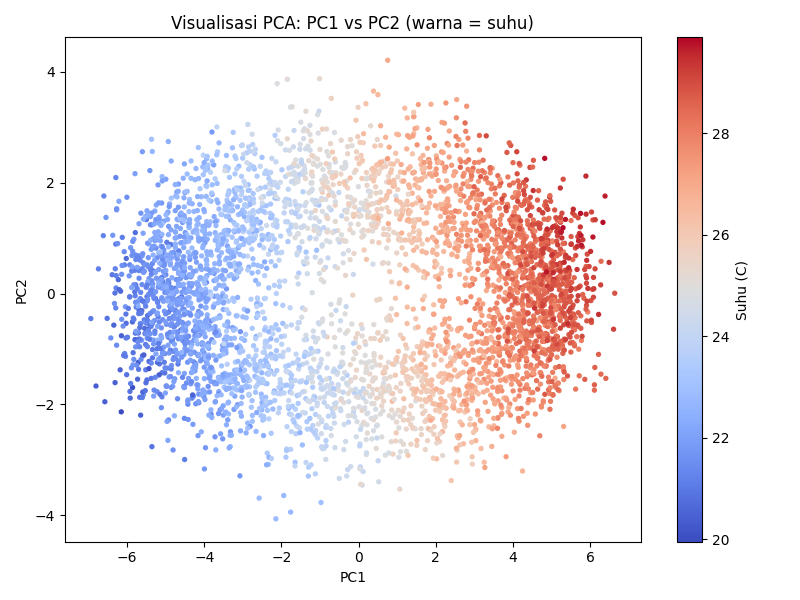

In [3]:
r = subprocess.run([sys.executable, "scripts/plot_pca_room.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/room_pca_scatter.png")

## Penutup

3 komponen utama menjelaskan sekitar 76% variasi data (PC1 saja sekitar 60%). Struktur
pola harian tampak di ruang PCA dan berkaitan dengan suhu. Perluasan lanjutan PCA ada di
Hands-on 16 perluasan (deteksi perubahan pola di ruang komponen utama).

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 16 dalam urutan buku) sebagai panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 6. Mengapa perlu standardisasi?

PCA sensitif terhadap skala. Misalnya:
- temperature_c mungkin berada di kisaran 20–30,
- humidity_pct di 40–80,
- comfort_index_simple bisa lebih besar,
- hour_sin dan hour_cos di -1 sampai 1.
Karena itu, fitur harus dinormalisasi atau distandarisasi lebih dulu. Literatur feature
engineering juga menyinggung bahwa transformasi seperti scaling atau
normalization membantu performa model dan membuat data lebih konsisten.

### 8. Interpretasi hasil PCA

Yang perlu dilihat:
- apakah 2–3 komponen pertama sudah menjelaskan porsi besar variasi data,
- apakah data yang awalnya banyak kolom kini bisa dipadatkan,
- apakah pola harian atau cluster kasar mulai tampak di ruang PCA.
PCA tidak langsung memberi makna fisik yang sesederhana suhu atau kelembaban,
tetapi ia sangat berguna untuk:

merangkum informasi,
mengurangi redundansi,
membantu visualisasi,
dan menyiapkan model yang lebih ringan.

## Jawaban dari data: Interpretasi hasil PCA (Hands-on 16): jawaban dari data

In [4]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
df = pd.read_csv("data/processed/room_30days_features.csv").dropna()
cols = [c for c in df.columns if c not in ("timestamp", "device_id")]
X = StandardScaler().fit_transform(df[cols])
p = PCA(n_components=3).fit(X)
print("Explained variance ratio:", p.explained_variance_ratio_.round(4), "total:", round(p.explained_variance_ratio_.sum(), 4))
load = pd.DataFrame(p.components_.T, index=cols, columns=["pc1", "pc2", "pc3"])
print("Fitur berkontribusi terbesar pada PC1:")
print(load["pc1"].abs().sort_values(ascending=False).head(5).round(3))

Explained variance ratio: [0.5482 0.1125 0.0747] total: 0.7354
Fitur berkontribusi terbesar pada PC1:
temp_ma_6          0.273
temp_ma_3          0.272
temp_roll_min_6    0.272
temp_roll_max_6    0.272
hour_cos           0.271
Name: pc1, dtype: float64
